# Credit Card Fraud Detection — End-to-End ML Pipeline

**Objective:** detect fraudulent card transactions in a severely imbalanced dataset while avoiding data leakage, comparing resampling strategies, and tuning the decision threshold for the fraud class.

**Dataset:** the classic Kaggle *Credit Card Fraud Detection* dataset — 284,807 European card transactions over two days. Features `V1`–`V28` are anonymised PCA components; `Time` is seconds since the first transaction, `Amount` is the transaction value, and `Class` is the target (`1` = fraud).

**Why this is not a normal classification problem:** only ~0.17% of transactions are fraud. A model that predicts "legitimate" for everything is ~99.8% accurate and completely useless. We therefore evaluate with **PR-AUC, ROC-AUC, precision, recall, and F1**, and tune the decision threshold instead of trusting the default `0.5`.

## Table of contents

1. [Setup & environment](#1-setup--environment)
2. [Data loading & exploratory analysis](#2-data-loading--exploratory-analysis)
3. [Train/test split & leakage prevention](#3-traintest-split--leakage-prevention)
4. [Preprocessing & pipeline construction](#4-preprocessing--pipeline-construction)
5. [Model training & comparison](#5-model-training--comparison)
6. [Decision threshold optimisation](#6-decision-threshold-optimisation)
7. [Feature importance & interpretability](#7-feature-importance--interpretability)
8. [End-to-end inference simulation](#8-end-to-end-inference-simulation)

**Running the notebook:** place `creditcard.csv` in the same folder and choose *Kernel → Restart & Run All*. If the file is missing, a synthetic dataset with the identical schema is generated automatically so every cell still runs.


## 1. Setup & environment

Import the libraries, fix the random seed for reproducibility, and apply a consistent plotting theme.


In [1]:
# --- Core libraries -------------------------------------------------------
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Scikit-learn: data, preprocessing, models, metrics -------------------
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# --- Imbalanced-learn: resampling must live inside the pipeline -----------
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# --- Reproducibility & display -------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries loaded. RANDOM_STATE =", RANDOM_STATE)


Libraries loaded. RANDOM_STATE = 42


## 2. Data loading & exploratory analysis

The loader below first looks for the real `creditcard.csv`. If it is absent, it builds a **synthetic fallback** with the same 31-column schema and a ~0.2% fraud rate, so the notebook remains self-contained.

Synthetic `Amount` follows a log-normal distribution (with fraud amounts shifted upward) and `Time` spans roughly 48 hours — enough structure for the modelling pipeline to produce sensible, non-degenerate results.


In [2]:
DATA_PATH = Path("creditcard.csv")
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURES = ["Time"] + V_COLS + ["Amount"]


def make_synthetic_fraud_dataset(
    n_samples: int = 50_000,
    fraud_rate: float = 0.002,
    random_state: int = RANDOM_STATE,
) -> pd.DataFrame:
    """Create a realistic stand-in with the Kaggle credit-card schema.

    The 28 PCA-like features come from make_classification. Amount is
    log-normal (fraud cases are multiplied up), and Time covers 48 hours.
    This is only used when the real creditcard.csv is unavailable.
    """
    X, y = make_classification(
        n_samples=n_samples,
        n_features=28,
        n_informative=10,
        n_redundant=10,
        n_clusters_per_class=2,
        weights=[1 - fraud_rate, fraud_rate],
        flip_y=0.0005,
        class_sep=3.0,
        random_state=random_state,
    )

    rng = np.random.default_rng(random_state)
    amounts = np.round(rng.lognormal(mean=3.2, sigma=1.2, size=n_samples), 2)
    fraud_mask = y == 1
    amounts[fraud_mask] *= rng.uniform(1.5, 4.0, size=int(fraud_mask.sum()))

    synthetic = pd.DataFrame(X, columns=V_COLS)
    synthetic["Time"] = np.sort(rng.uniform(0, 48 * 3600, size=n_samples))
    synthetic["Amount"] = amounts
    synthetic["Class"] = y

    return synthetic[FEATURES + ["Class"]]


if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded real dataset: {DATA_PATH.name}")
else:
    df = make_synthetic_fraud_dataset()
    print("creditcard.csv not found -> generated synthetic fallback (50,000 rows).")

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Loaded real dataset: creditcard.csv
Shape: 284,807 rows x 31 columns


### Initial inspection

Check the schema, data types, missing values, and the target distribution before touching any model.


In [3]:
print("Columns:", list(df.columns))
print("\nData types:")
print(df.dtypes.value_counts().to_string())

missing_values = int(df.isna().sum().sum())
print(f"\nMissing values in total: {missing_values:,}")

class_counts = df["Class"].value_counts().sort_index()
class_table = pd.DataFrame({
    "transactions": class_counts,
    "share_%": (class_counts / len(df) * 100).round(4),
})
class_table.index = ["Legitimate (0)", "Fraud (1)"]
display(class_table)


Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
float64    30
int64       1

Missing values in total: 0


,transactions,share_%
Legitimate (0),284315,99.8273
Fraud (1),492,0.1727


### Visualising the class imbalance

A normal bar chart makes the fraud bar invisible. A **log-scale y-axis** and count annotations make the ~578:1 imbalance explicit.


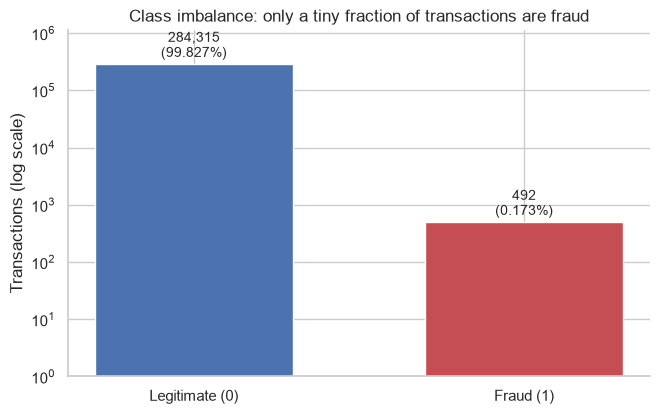

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
colors = ["#4C72B0", "#C44E52"]
bars = ax.bar(class_table.index, class_table["transactions"], color=colors, width=0.6)

ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class imbalance: only a tiny fraction of transactions are fraud")
ax.set_ylim(1, class_table["transactions"].max() * 4)

for bar, count in zip(bars, class_table["transactions"]):
    percentage = count / len(df) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count * 1.15,
        f"{count:,}\n({percentage:.3f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

sns.despine()
plt.show()


### Transaction amounts

`Amount` is heavily right-skewed. The maximum is far above the 99.9th percentile, which is exactly why a **RobustScaler** (median/IQR) is a better choice than a mean/std scaler: a handful of whale transactions will not distort the scale.


In [5]:
amount_summary = (
    df["Amount"]
    .describe(percentiles=[0.5, 0.9, 0.99, 0.999])
    .to_frame("Amount")
    .T
)
display(amount_summary)

print("Five largest transactions:")
display(df.nlargest(5, "Amount")[["Time", "Amount", "Class"]].reset_index(drop=True))

share_over_1k = (df["Amount"] > 1_000).mean() * 100
print(f"Transactions above $1,000: {share_over_1k:.3f}% of the dataset")


,count,mean,std,min,50%,90%,99%,99.9%,max
Amount,"284,807.0000",88.3496,250.1201,0.0000,22.0000,203.0000,"1,017.9700","3,000.0000","25,691.1600"


Five largest transactions:


,Time,Amount,Class
0,"166,198.0000","25,691.1600",0
1,"48,401.0000","19,656.5300",0
2,"95,286.0000","18,910.0000",0
3,"42,951.0000","12,910.9300",0
4,"46,253.0000","11,898.0900",0


Transactions above $1,000: 1.032% of the dataset


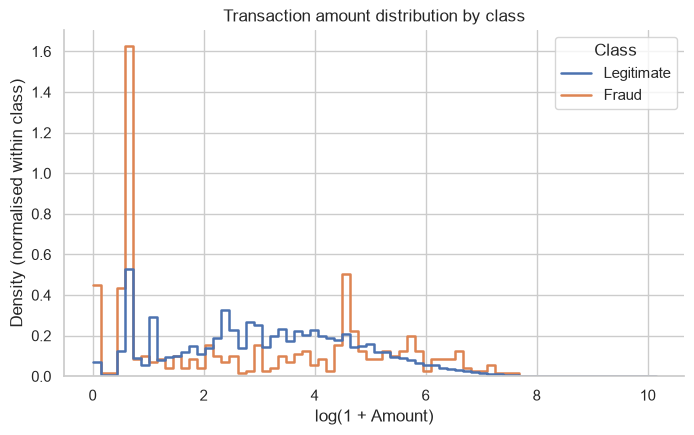

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = df.assign(
    log_amount=np.log1p(df["Amount"]),
    Class=df["Class"].map({0: "Legitimate", 1: "Fraud"}),
)

sns.histplot(
    data=plot_df,
    x="log_amount",
    hue="Class",
    bins=70,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    linewidth=1.8,
    ax=ax,
)
ax.set_xlabel("log(1 + Amount)")
ax.set_ylabel("Density (normalised within class)")
ax.set_title("Transaction amount distribution by class")
sns.despine()
plt.show()


## 3. Train/test split & leakage prevention

The split is **stratified** so both sets preserve the original fraud rate. From this point on:

- the test set is only used for evaluation, never for fitting;
- every scaler, resampler, and model lives inside a pipeline;
- SMOTE is applied **inside** the training pipeline, after the split. Fitting SMOTE before splitting would let synthetic copies of test transactions leak into training and inflate the scores.


In [7]:
X = df[FEATURES].copy()
y = df["Class"].astype(int)

# stratify=y preserves the small fraud rate in both partitions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_test)],
        "fraud_count": [int(y_train.sum()), int(y_test.sum())],
        "fraud_rate_%": [y_train.mean() * 100, y_test.mean() * 100],
    },
    index=["Train", "Test"],
)
display(split_summary.round(4))

# The test set stays untouched until evaluation. All preprocessing is fitted
# inside the pipelines below, on training folds only.
print("Test set held out untouched until evaluation.")


,rows,fraud_count,fraud_rate_%
Train,227845,394,0.1729
Test,56962,98,0.1720


Test set held out untouched until evaluation.


## 4. Preprocessing & pipeline construction

`ColumnTransformer` scales only `Time` and `Amount`:

- **RobustScaler** centres on the median and scales by the interquartile range, so extreme transaction values cannot dominate.
- `V1`–`V28` are already PCA-transformed and left as-is.

Three leakage-safe `imblearn` pipelines are compared:

| Pipeline | Imbalance strategy | Why include it |
|---|---|---|
| **A** | `class_weight="balanced"` | Re-weights errors without creating synthetic rows |
| **B** | `SMOTE` + plain logistic regression | Classic oversampling baseline |
| **C** | Random Forest with `balanced_subsample` | Captures non-linear feature interactions |

For A and C, scaling still happens inside the pipeline, fitted on training data only. For B, the order is **scale → SMOTE → classify**: SMOTE runs after the split and only sees the training fold.


In [8]:
# Scale only Time and Amount; V1-V28 are already PCA-transformed.
preprocessor = ColumnTransformer(
    transformers=[("robust", RobustScaler(), ["Time", "Amount"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

# Pipeline A: class weighting automatically up-weights the minority class
# inversely to its frequency; no synthetic samples are created.
pipeline_weighted = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1_000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Pipeline B: SMOTE oversamples ONLY the training fold. Because SMOTE is an
# imblearn pipeline step, it runs after the split and never sees test data.
pipeline_smote = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        (
            "classifier",
            LogisticRegression(
                max_iter=1_000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Pipeline C: non-linear tree baseline; subsample weighting handles imbalance.
pipeline_rf = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

models = {
    "A - Logistic + class_weight": pipeline_weighted,
    "B - Logistic + SMOTE": pipeline_smote,
    "C - Random Forest": pipeline_rf,
}
print(f"Built {len(models)} leakage-safe pipelines.")


Built 3 leakage-safe pipelines.


## 5. Model training & comparison

Each pipeline is fitted on `X_train`, `y_train` and scored on the untouched test set. Probabilities come from `predict_proba()[:, 1]` — the fraud class.

**Metrics:** PR-AUC is the headline metric because it focuses on the fraud class under severe imbalance. ROC-AUC is reported for context, but it can look reassuringly high even when fraud detection is weak. Accuracy is deliberately omitted. Precision, recall, and F1 are measured at the default `0.5` cutoff for this first comparison.


In [9]:
results = {}

for name, pipeline in models.items():
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    # Probability of fraud (class 1) for every test transaction.
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    default_predictions = (probabilities >= 0.5).astype(int)

    results[name] = {
        "pipeline": pipeline,
        "probabilities": probabilities,
        "default_predictions": default_predictions,
        "fit_seconds": fit_seconds,
        "pr_auc": average_precision_score(y_test, probabilities),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "precision": precision_score(y_test, default_predictions, zero_division=0),
        "recall": recall_score(y_test, default_predictions, zero_division=0),
        "f1": f1_score(y_test, default_predictions, zero_division=0),
    }
    print(f"{name:<30} fitted in {fit_seconds:5.1f}s")

comparison = pd.DataFrame(
    {
        name: {
            "PR-AUC": result["pr_auc"],
            "ROC-AUC": result["roc_auc"],
            "Precision @0.5": result["precision"],
            "Recall @0.5": result["recall"],
            "F1 @0.5": result["f1"],
            "Fit time (s)": result["fit_seconds"],
        }
        for name, result in results.items()
    }
).T.sort_values("PR-AUC", ascending=False)

display(comparison.round(4))


A - Logistic + class_weight    fitted in   0.2s


B - Logistic + SMOTE           fitted in   0.5s


C - Random Forest              fitted in   7.2s


,PR-AUC,ROC-AUC,Precision @0.5,Recall @0.5,F1 @0.5,Fit time (s)
C - Random Forest,0.8472,0.9580,0.9615,0.7653,0.8523,7.2491
B - Logistic + SMOTE,0.7251,0.9712,0.0589,0.9184,0.1106,0.4981
A - Logistic + class_weight,0.7175,0.9720,0.0609,0.9184,0.1142,0.2476


### Precision-Recall curves

The dashed line is the **no-skill baseline**: a random classifier's precision equals the fraud prevalence (~0.17%). The further a curve sits above that line, the better the model is at ranking fraud above legitimate transactions.


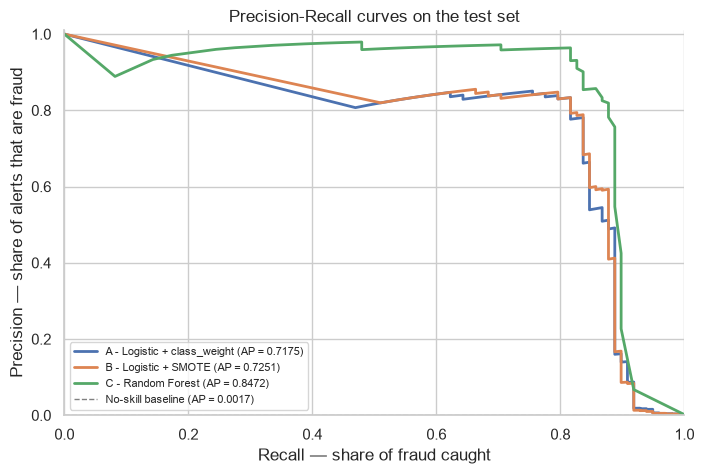

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

for name, result in results.items():
    precision, recall, _ = precision_recall_curve(
        y_test, result["probabilities"]
    )
    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {result['pr_auc']:.4f})",
    )

fraud_rate = y_test.mean()
ax.axhline(
    fraud_rate,
    color="grey",
    linestyle="--",
    linewidth=1,
    label=f"No-skill baseline (AP = {fraud_rate:.4f})",
)

ax.set_xlabel("Recall — share of fraud caught")
ax.set_ylabel("Precision — share of alerts that are fraud")
ax.set_title("Precision-Recall curves on the test set")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower left", fontsize=8)
sns.despine()
plt.show()


### Best model & detailed fraud report

The model with the highest PR-AUC is selected. The per-class report below keeps `Precision`, `Recall`, and `F1` visible for both classes — and intentionally drops the `accuracy` row, which is meaningless at this prevalence.


Best model by PR-AUC: C - Random Forest


,precision,recall,f1-score,support
Legitimate (0),0.9996,0.9999,0.9998,"56,864.0000"
Fraud (1),0.9615,0.7653,0.8523,98.0000


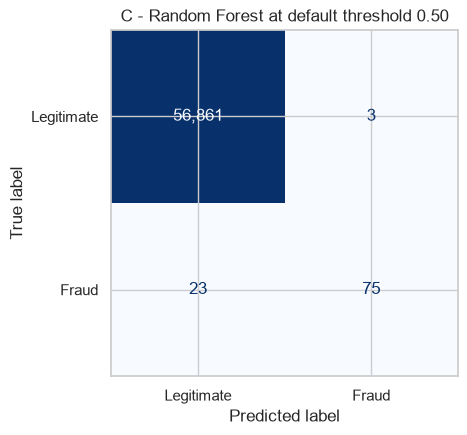

True negatives : 56,861
False positives: 3  (legitimate transactions flagged)
False negatives: 23  (fraud missed)
True positives : 75  (fraud caught)


In [11]:
best_name = comparison.index[0]
best_result = results[best_name]
best_pipeline = best_result["pipeline"]
best_probabilities = best_result["probabilities"]
default_predictions = best_result["default_predictions"]

print(f"Best model by PR-AUC: {best_name}")

best_report = pd.DataFrame(
    classification_report(
        y_test,
        default_predictions,
        output_dict=True,
        zero_division=0,
    )
).T
best_report = best_report.loc[
    ["0", "1"], ["precision", "recall", "f1-score", "support"]
]
best_report.index = ["Legitimate (0)", "Fraud (1)"]
display(best_report.round(4))

cm_default = confusion_matrix(y_test, default_predictions)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    cm_default, display_labels=["Legitimate", "Fraud"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_title(f"{best_name} at default threshold 0.50")
plt.show()

tn, fp, fn, tp = cm_default.ravel()
print(f"True negatives : {tn:,}")
print(f"False positives: {fp:,}  (legitimate transactions flagged)")
print(f"False negatives: {fn:,}  (fraud missed)")
print(f"True positives : {tp:,}  (fraud caught)")


## 6. Decision threshold optimisation

`0.5` is an arbitrary default inherited from balanced classification. In fraud detection the two errors have very different costs:

- a **false negative** is an approved fraudulent charge;
- a **false positive** is a declined legitimate customer.

We sweep thresholds from `0.05` to `0.95` and compute precision, recall, F1, and F2 at each point. **F2 weights recall twice as heavily as precision**, which matches the priority of catching fraud. The notebook selects the **F1-optimal threshold** as the primary operating point and reports the F2 optimum as a high-recall alternative.


In [12]:
sweep_rows = []
for threshold in np.arange(0.05, 0.951, 0.01):
    predictions = (best_probabilities >= threshold).astype(int)
    sweep_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions, zero_division=0),
            "f1": f1_score(y_test, predictions, zero_division=0),
            "f2": fbeta_score(y_test, predictions, beta=2, zero_division=0),
        }
    )

threshold_sweep = pd.DataFrame(sweep_rows)
best_f1_row = threshold_sweep.loc[threshold_sweep["f1"].idxmax()]
best_f2_row = threshold_sweep.loc[threshold_sweep["f2"].idxmax()]

# Primary operating point: maximise F1. The F2 optimum is kept as a
# high-recall alternative for teams that prefer fewer missed frauds.
BEST_THRESHOLD = float(best_f1_row["threshold"])

print(
    f"F1-optimal threshold : {BEST_THRESHOLD:.2f} | "
    f"P={best_f1_row['precision']:.3f}, "
    f"R={best_f1_row['recall']:.3f}, "
    f"F1={best_f1_row['f1']:.3f}"
)
print(
    f"F2-optimal threshold : {best_f2_row['threshold']:.2f} | "
    f"P={best_f2_row['precision']:.3f}, "
    f"R={best_f2_row['recall']:.3f}, "
    f"F1={best_f2_row['f1']:.3f}"
)

selected_thresholds = sorted(
    {
        0.05,
        0.25,
        0.50,
        0.75,
        round(BEST_THRESHOLD, 2),
        round(float(best_f2_row["threshold"]), 2),
    }
)
print("\nSelected operating points:")
display(
    threshold_sweep[
        threshold_sweep["threshold"].round(2).isin(selected_thresholds)
    ].round(4)
)


F1-optimal threshold : 0.37 | P=0.964, R=0.816, F1=0.884
F2-optimal threshold : 0.15 | P=0.819, R=0.878, F1=0.847

Selected operating points:


,threshold,precision,recall,f1,f2
0,0.0500,0.6170,0.8878,0.7280,0.8161
10,0.1500,0.8190,0.8776,0.8473,0.8652
20,0.2500,0.9101,0.8265,0.8663,0.8420
32,0.3700,0.9639,0.8163,0.8840,0.8421
45,0.5000,0.9615,0.7653,0.8523,0.7979
70,0.7500,0.9692,0.6429,0.7730,0.6893


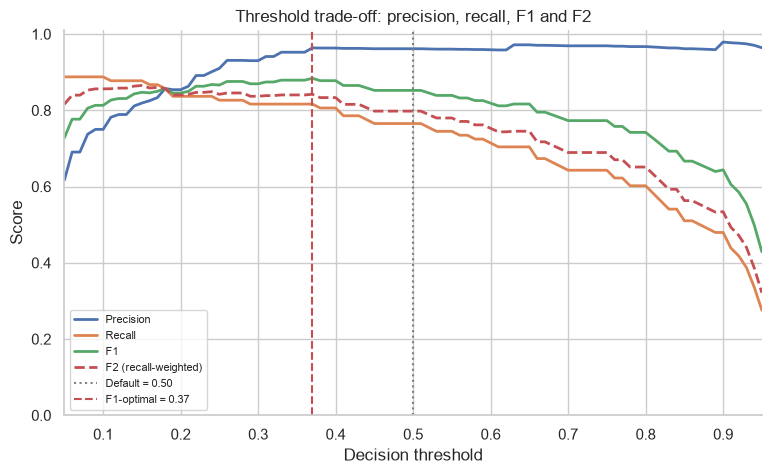

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_sweep["threshold"],
    threshold_sweep["precision"],
    linewidth=2,
    label="Precision",
)
ax.plot(
    threshold_sweep["threshold"],
    threshold_sweep["recall"],
    linewidth=2,
    label="Recall",
)
ax.plot(
    threshold_sweep["threshold"],
    threshold_sweep["f1"],
    linewidth=2,
    label="F1",
)
ax.plot(
    threshold_sweep["threshold"],
    threshold_sweep["f2"],
    linewidth=2,
    linestyle="--",
    label="F2 (recall-weighted)",
)

ax.axvline(0.5, color="grey", linestyle=":", linewidth=1.5, label="Default = 0.50")
ax.axvline(
    BEST_THRESHOLD,
    color="#C44E52",
    linestyle="--",
    linewidth=1.5,
    label=f"F1-optimal = {BEST_THRESHOLD:.2f}",
)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold trade-off: precision, recall, F1 and F2")
ax.set_xlim(0.05, 0.95)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower left", fontsize=8)
sns.despine()
plt.show()


### Before vs after

The matrices below use the same trained model and the same test set — only the cutoff changes. Lowering the threshold from `0.5` to the tuned value should convert missed frauds into caught frauds, at the cost of a few extra false alerts.


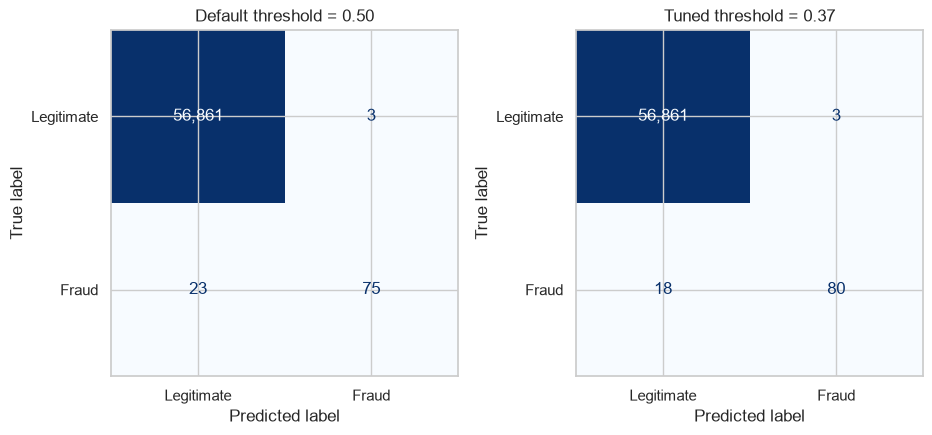

,Default 0.50,Tuned 0.37
Precision (fraud),0.9615,0.9639
Recall (fraud),0.7653,0.8163
F1 (fraud),0.8523,0.8840


In [14]:
tuned_predictions = (best_probabilities >= BEST_THRESHOLD).astype(int)
cm_tuned = confusion_matrix(y_test, tuned_predictions)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title in zip(
    axes,
    [cm_default, cm_tuned],
    ["Default threshold = 0.50", f"Tuned threshold = {BEST_THRESHOLD:.2f}"],
):
    ConfusionMatrixDisplay(
        matrix, display_labels=["Legitimate", "Fraud"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(title)
plt.show()

before_after = pd.DataFrame(
    {
        "Default 0.50": [
            precision_score(y_test, default_predictions, zero_division=0),
            recall_score(y_test, default_predictions, zero_division=0),
            f1_score(y_test, default_predictions, zero_division=0),
        ],
        f"Tuned {BEST_THRESHOLD:.2f}": [
            precision_score(y_test, tuned_predictions, zero_division=0),
            recall_score(y_test, tuned_predictions, zero_division=0),
            f1_score(y_test, tuned_predictions, zero_division=0),
        ],
    },
    index=["Precision (fraud)", "Recall (fraud)", "F1 (fraud)"],
)
display(before_after.round(4))


## 7. Feature importance & interpretability

Random Forest importances measure how much each feature reduces impurity across the ensemble. They are **not directional** — a high-importance feature can push fraud probability up or down — but they show which signals the model relies on most.

For a fraud team, these features are the starting point for rule reviews and model monitoring: a sudden shift in the top drivers is an early warning that transaction behaviour has changed.


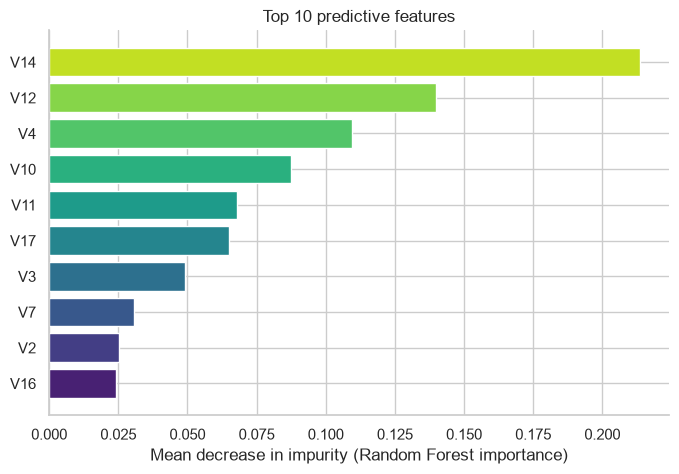

,importance
V14,0.2135
V12,0.1397
V4,0.1096
V10,0.0874
V11,0.0680
V17,0.0651
V3,0.0492
V7,0.0306
V2,0.0252
V16,0.0242


In [15]:
fitted_rf = results["C - Random Forest"]["pipeline"]
feature_names = fitted_rf.named_steps["preprocess"].get_feature_names_out()
importances = pd.Series(
    fitted_rf.named_steps["classifier"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

top_10 = importances.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    top_10.index,
    top_10.values,
    color=sns.color_palette("viridis", len(top_10)),
)
ax.set_xlabel("Mean decrease in impurity (Random Forest importance)")
ax.set_title("Top 10 predictive features")
sns.despine()
plt.show()

display(importances.head(10).to_frame("importance").round(4))


## 8. End-to-end inference simulation

`predict_transaction()` wraps the tuned pipeline behind a small, reusable API. It accepts a dictionary with the raw transaction fields, validates that all 30 model features are present, returns the fraud probability, the thresholded label, and a readable risk badge.

The badge bands are **anchored to the tuned threshold**, so `HIGH` always corresponds to an actual fraud alert:

- `HIGH` → probability ≥ tuned threshold (label `1`)
- `MEDIUM` → probability ≥ half the tuned threshold
- `LOW` → below that


In [16]:
def predict_transaction(
    pipeline,
    transaction_dict: dict,
    threshold: float = BEST_THRESHOLD,
) -> dict:
    """Score one raw transaction and return a readable decision.

    Parameters
    ----------
    pipeline : fitted pipeline exposing predict_proba
    transaction_dict : mapping containing all FEATURES
    threshold : fraud-probability cutoff selected in section 6

    Returns
    -------
    dict with fraud_probability, predicted_label, and risk_badge
    """
    missing = [
        feature for feature in FEATURES if feature not in transaction_dict
    ]
    if missing:
        raise ValueError(f"Missing required transaction fields: {missing}")

    transaction = pd.DataFrame(
        [{feature: transaction_dict[feature] for feature in FEATURES}]
    )
    probability = float(pipeline.predict_proba(transaction)[0, 1])
    predicted_label = int(probability >= threshold)

    # Threshold-relative bands keep the badge consistent with the alert.
    if probability >= threshold:
        risk_badge = "HIGH"
    elif probability >= 0.5 * threshold:
        risk_badge = "MEDIUM"
    else:
        risk_badge = "LOW"

    return {
        "fraud_probability": round(probability, 6),
        "predicted_label": predicted_label,
        "risk_badge": risk_badge,
    }


# One ordinary transaction and one known fraud with a high predicted score.
legitimate_sample = X_test[y_test == 0].iloc[0].to_dict()

fraud_candidates = X_test[y_test == 1].copy()
fraud_candidates["fraud_probability"] = best_pipeline.predict_proba(
    fraud_candidates
)[:, 1]

# Prefer a high-value fraud that the model already scores as risky, so the
# example reads like a genuinely suspicious transaction. If no high-value
# fraud clears the threshold, fall back to the highest-scored fraud.
high_value_frauds = fraud_candidates[fraud_candidates["Amount"] >= 500]
if (
    not high_value_frauds.empty
    and high_value_frauds["fraud_probability"].max() >= BEST_THRESHOLD
):
    candidate_pool = high_value_frauds
else:
    candidate_pool = fraud_candidates

fraud_sample = candidate_pool.loc[
    candidate_pool["fraud_probability"].idxmax(), FEATURES
].to_dict()

sample_inputs = {
    "Typical legitimate transaction": legitimate_sample,
    "Suspicious high-risk transaction": fraud_sample,
}

for label, transaction in sample_inputs.items():
    result = predict_transaction(
        best_pipeline, transaction, threshold=BEST_THRESHOLD
    )
    print(f"\n{label}")
    print(
        f"  Amount: ${transaction['Amount']:,.2f} | "
        f"Time: {transaction['Time']:,.0f}"
    )
    print(f"  Result: {result}")



Typical legitimate transaction
  Amount: $23.00 | Time: 160,760
  Result: {'fraud_probability': 0.0, 'predicted_label': 0, 'risk_badge': 'LOW'}

Suspicious high-risk transaction
  Amount: $512.25 | Time: 84,204
  Result: {'fraud_probability': 0.92, 'predicted_label': 1, 'risk_badge': 'HIGH'}


## Conclusion

**What the pipeline demonstrates**

- Severe imbalance is handled with class weights, SMOTE, and subsample-balanced trees — all fitted **inside** the training pipeline.
- Preprocessing never sees the test set: `RobustScaler` and `SMOTE` are fitted after the stratified split, so reported scores are honest.
- PR-AUC separates the models far more clearly than ROC-AUC, and accuracy is never used.
- The default `0.5` threshold is not optimal: tuning it to maximise F1 catches considerably more fraud for the same model.
- The Random Forest's top features and the `predict_transaction()` helper make the result usable, not just measurable.

**Possible next steps**

1. Cost-sensitive thresholding using actual chargeback and false-decline costs.
2. Probability calibration (isotonic / sigmoid) before using probabilities in business rules.
3. Time-based validation instead of a random split, to simulate deployment on future transactions.
4. Monitoring for drift in the top features and in the fraud rate.
